In [4]:
#202432023_HaikalFadhillahMukti

import pandas as pd
import numpy as np
import re
import random
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from collections import Counter
import copy

In [5]:
#202432023_HaikalFadhillahMukti

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

df = pd.read_csv("Corpus Bahasa Indonesia Label.csv")

print("Ukuran Dataset:", df.shape)

print("\n5 Data Pertama:")
display(df.head())

Device: cpu
Ukuran Dataset: (12609, 2)

5 Data Pertama:


,kalimat,sentiment
0,Kalimat-kalimat tersebut adalah sebagai berikut,0
1,Manusia membutuhkan makanan dan air supaya men...,1
2,Tanaman hijau menggunakan air untuk membuat ma...,0
3,Tanaman yang tidak mendapat air akan layu dan ...,1
4,Keberhasilan belajar murid tidak hanya bergant...,1


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12609 entries, 0 to 12608
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   kalimat    12609 non-null  object
 1   sentiment  12609 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 197.1+ KB

Jumlah Data Kosong:
kalimat      0
sentiment    0
dtype: int64

Jumlah Data Duplikat:
1516

Distribusi Label Sentimen:
sentiment
0    6464
2    3319
1    2826
Name: count, dtype: int64

Jumlah Data Setiap Label:


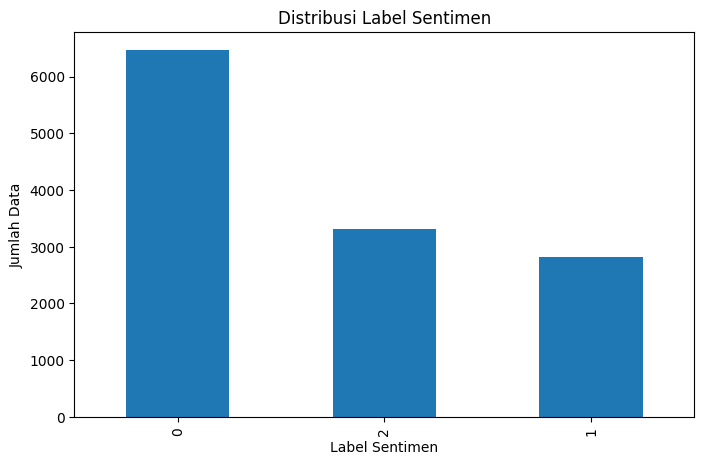

In [6]:
#202432023_HaikalFadhillahMukti

print("Informasi Dataset:")
df.info()

print("\nJumlah Data Kosong:")
print(df.isnull().sum())

print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

print("\nDistribusi Label Sentimen:")
print(df["sentiment"].value_counts())

print("\nJumlah Data Setiap Label:")
df["sentiment"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribusi Label Sentimen")
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Data")
plt.show()

In [7]:
#202432023_HaikalFadhillahMukti

df = df.dropna(subset=["kalimat", "sentiment"])

df = df.drop_duplicates(subset=["kalimat"])

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["kalimat"] = df["kalimat"].apply(clean_text)

df = df[df["kalimat"] != ""]

print("Jumlah Data Setelah Preprocessing:", len(df))

display(df.head())

Jumlah Data Setelah Preprocessing: 11093


,kalimat,sentiment
0,kalimat kalimat tersebut adalah sebagai berikut,0
1,manusia membutuhkan makanan dan air supaya men...,1
2,tanaman hijau menggunakan air untuk membuat ma...,0
3,tanaman yang tidak mendapat air akan layu dan ...,1
4,keberhasilan belajar murid tidak hanya bergant...,1


In [8]:
#202432023_HaikalFadhillahMukti

label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(df["sentiment"])

print("Pemetaan Label:")
for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)

X = df["kalimat"].values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train
)

print("\nJumlah Data Training:", len(X_train))
print("Jumlah Data Validation:", len(X_val))
print("Jumlah Data Testing:", len(X_test))

Pemetaan Label:
0 = 0
1 = 1
2 = 2

Jumlah Data Training: 7986
Jumlah Data Validation: 888
Jumlah Data Testing: 2219


In [9]:
#202432023_HaikalFadhillahMukti

MAX_VOCAB = 20000
MAX_LEN = 40

word_counter = Counter()

for sentence in X_train:
    tokens = sentence.split()
    word_counter.update(tokens)

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in word_counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

print("Jumlah Vocabulary:", len(vocab))

def encode_text(text):
    tokens = text.split()

    if len(tokens) == 0:
        tokens = ["<UNK>"]

    encoded = [
        vocab.get(word, vocab["<UNK>"])
        for word in tokens[:MAX_LEN]
    ]

    length = len(encoded)

    encoded += [vocab["<PAD>"]] * (MAX_LEN - length)

    return encoded, length

def prepare_data(texts):
    encoded_data = []
    lengths = []

    for text in texts:
        encoded, length = encode_text(text)

        encoded_data.append(encoded)
        lengths.append(length)

    return (
        torch.tensor(encoded_data, dtype=torch.long),
        torch.tensor(lengths, dtype=torch.long)
    )

X_train_tensor, train_lengths = prepare_data(X_train)
X_val_tensor, val_lengths = prepare_data(X_val)
X_test_tensor, test_lengths = prepare_data(X_test)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("Ukuran Tensor Training:", X_train_tensor.shape)
print("Ukuran Tensor Validation:", X_val_tensor.shape)
print("Ukuran Tensor Testing:", X_test_tensor.shape)

Jumlah Vocabulary: 12112
Ukuran Tensor Training: torch.Size([7986, 40])
Ukuran Tensor Validation: torch.Size([888, 40])
Ukuran Tensor Testing: torch.Size([2219, 40])


In [10]:
#202432023_HaikalFadhillahMukti

BATCH_SIZE = 128

train_dataset = TensorDataset(
    X_train_tensor,
    train_lengths,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    val_lengths,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    test_lengths,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE
)

print("DataLoader berhasil dibuat.")

DataLoader berhasil dibuat.


In [11]:
#202432023_HaikalFadhillahMukti

class LSTMModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes):
        super(LSTMModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x, lengths):

        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        last_output = output[
            torch.arange(output.size(0), device=output.device),
            lengths.to(output.device) - 1
        ]

        dropped = self.dropout(last_output)

        result = self.fc(dropped)

        return result

model = LSTMModel(
    vocab_size=len(vocab),
    embedding_dim=64,
    hidden_dim=64,
    num_classes=len(label_encoder.classes_)
).to(device)

print(model)

LSTMModel(
  (embedding): Embedding(12112, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)


In [12]:
#202432023_HaikalFadhillahMukti

EPOCHS = 10
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_model = None

print("Konfigurasi Training:")
print("Epoch:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Optimizer: Adam")
print("Loss Function: CrossEntropyLoss")

Konfigurasi Training:
Epoch: 10
Learning Rate: 0.001
Optimizer: Adam
Loss Function: CrossEntropyLoss


In [13]:
#202432023_HaikalFadhillahMukti

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0
    all_predictions = []
    all_labels = []

    for inputs, lengths, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs, lengths)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    train_loss = total_loss / len(train_loader)

    train_acc = accuracy_score(
        all_labels,
        all_predictions
    )

    model.eval()

    val_total_loss = 0
    val_predictions = []
    val_labels = []

    with torch.no_grad():

        for inputs, lengths, labels in val_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs, lengths)

            loss = criterion(outputs, labels)

            val_total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            val_predictions.extend(predictions.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss = val_total_loss / len(val_loader)

    val_acc = accuracy_score(
        val_labels,
        val_predictions
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

model.load_state_dict(best_model)

Epoch [1/10] Train Loss: 1.0516 Train Acc: 0.4621 Val Loss: 1.0188 Val Acc: 0.5068
Epoch [2/10] Train Loss: 0.9959 Train Acc: 0.5222 Val Loss: 0.9842 Val Acc: 0.5214
Epoch [3/10] Train Loss: 0.9417 Train Acc: 0.5552 Val Loss: 0.9438 Val Acc: 0.5327
Epoch [4/10] Train Loss: 0.8684 Train Acc: 0.6064 Val Loss: 0.9088 Val Acc: 0.5586
Epoch [5/10] Train Loss: 0.7747 Train Acc: 0.6630 Val Loss: 0.8850 Val Acc: 0.5811
Epoch [6/10] Train Loss: 0.6763 Train Acc: 0.7164 Val Loss: 0.8610 Val Acc: 0.6014
Epoch [7/10] Train Loss: 0.5741 Train Acc: 0.7655 Val Loss: 0.9258 Val Acc: 0.6137
Epoch [8/10] Train Loss: 0.4875 Train Acc: 0.8090 Val Loss: 0.9309 Val Acc: 0.6273
Epoch [9/10] Train Loss: 0.4079 Train Acc: 0.8476 Val Loss: 0.9488 Val Acc: 0.6374
Epoch [10/10] Train Loss: 0.3228 Train Acc: 0.8866 Val Loss: 1.0176 Val Acc: 0.6610


<All keys matched successfully>

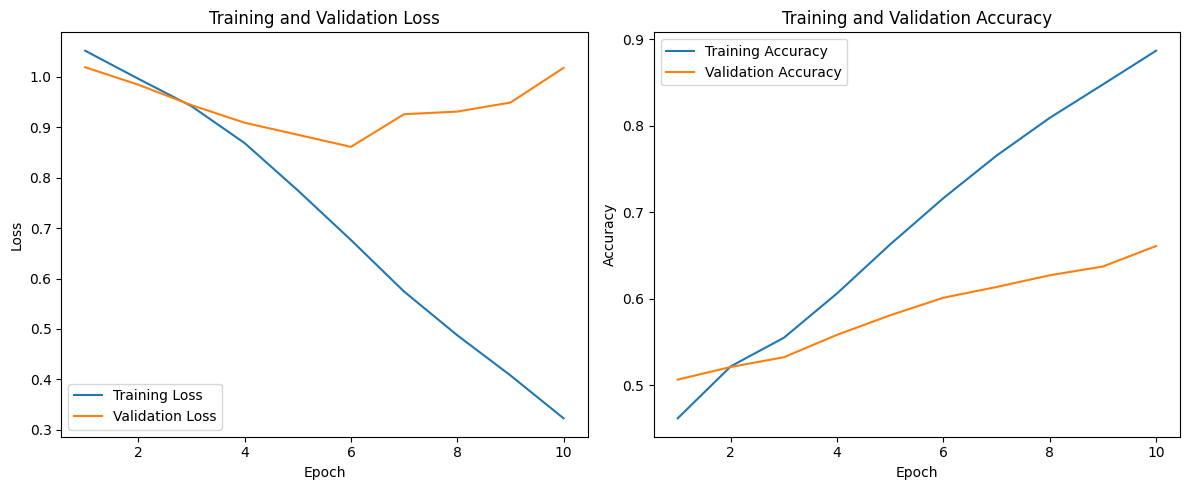

In [14]:
#202432023_HaikalFadhillahMukti

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
#202432023_HaikalFadhillahMukti

model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for inputs, lengths, labels in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs, lengths)

        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(y_true, y_pred)

print("Akurasi Model:", round(test_accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            str(label) for label in label_encoder.classes_
        ],
        zero_division=0
    )
)

Akurasi Model: 60.57 %

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.77      0.74      1119
           1       0.50      0.37      0.43       506
           2       0.46      0.48      0.47       594

    accuracy                           0.61      2219
   macro avg       0.56      0.54      0.55      2219
weighted avg       0.60      0.61      0.60      2219



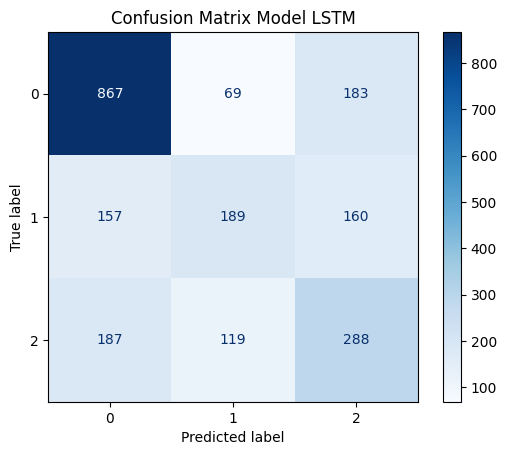

In [16]:
#202432023_HaikalFadhillahMukti

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

display_labels = [
    str(label) for label in label_encoder.classes_
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix Model LSTM")
plt.show()

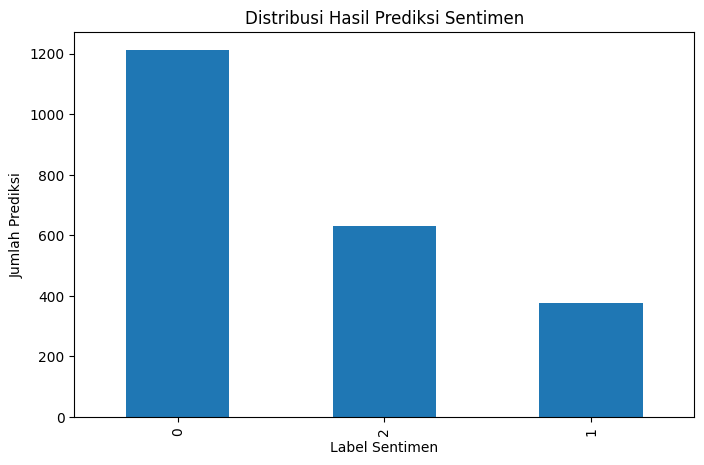

In [17]:
#202432023_HaikalFadhillahMukti

predicted_labels = label_encoder.inverse_transform(
    np.array(y_pred)
)

prediction_counts = pd.Series(
    predicted_labels
).value_counts()

plt.figure(figsize=(8, 5))

prediction_counts.plot(
    kind="bar"
)

plt.title("Distribusi Hasil Prediksi Sentimen")
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Prediksi")

plt.show()

In [18]:
#202432023_HaikalFadhillahMukti

model.eval()

sample_texts = [
    "pelayanan sangat bagus dan memuaskan",
    "produk ini sangat mengecewakan",
    "barang sudah diterima"
]

for text in sample_texts:

    cleaned = clean_text(text)

    encoded, length = encode_text(cleaned)

    input_tensor = torch.tensor(
        [encoded],
        dtype=torch.long
    ).to(device)

    length_tensor = torch.tensor(
        [length],
        dtype=torch.long
    )

    with torch.no_grad():

        output = model(input_tensor, length_tensor)

        probabilities = torch.softmax(output, dim=1)

        confidence, prediction = torch.max(
            probabilities,
            dim=1
        )

    predicted_label = label_encoder.inverse_transform(
        prediction.cpu().numpy()
    )[0]

    print("Kalimat:", text)
    print("Prediksi Label:", predicted_label)
    print("Confidence Score:", round(confidence.item() * 100, 2), "%")
    print("-" * 40)

Kalimat: pelayanan sangat bagus dan memuaskan
Prediksi Label: 1
Confidence Score: 48.53 %
----------------------------------------
Kalimat: produk ini sangat mengecewakan
Prediksi Label: 1
Confidence Score: 53.32 %
----------------------------------------
Kalimat: barang sudah diterima
Prediksi Label: 0
Confidence Score: 50.3 %
----------------------------------------
